# Probabilidades e Inferencias Estatisticas

Este notebook foi organizado para avaliar probabilidade empirica, probabilidade condicional e inferencia estatistica no contexto de risco de credito.

## Escopo

1. Carregar a base com `pandas`.
2. Estimar probabilidades empiricas relevantes para inadimplencia.
3. Analisar probabilidades condicionais e uma leitura pratica de Bayes.
4. Construir intervalos de confianca por bootstrap.
5. Executar testes de hipotese para comparar grupos e associacoes.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

ROOT_DIR = Path.cwd().resolve().parent if Path.cwd().name == 'notebook' else Path.cwd().resolve()
if str(ROOT_DIR / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT_DIR / 'src'))

from credit_risk.datasets import load_credit_risk_dataset

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 6)

D:\dev\credit_risk_v2\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = load_credit_risk_dataset()

print('Dataset carregado de: MinIO (manifesto latest do projeto)')
print(f'Dimensao: {df.shape[0]:,} linhas x {df.shape[1]} colunas')
display(df.head())

Dataset carregado de: D:\dev\credit_risk_v2\data\credit_risk_dataset.csv
Dimensao: 32,581 linhas x 12 colunas


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0000,PERSONAL,D,35000,16.0200,1,0.5900,Y,3
1,21,9600,OWN,5.0000,EDUCATION,B,1000,11.1400,0,0.1000,N,2
2,25,9600,MORTGAGE,1.0000,MEDICAL,C,5500,12.8700,1,0.5700,N,3
3,23,65500,RENT,4.0000,MEDICAL,C,35000,15.2300,1,0.5300,N,2
4,24,54400,RENT,8.0000,MEDICAL,C,35000,14.2700,1,0.5500,Y,4


## 1. Preparacao de segmentos probabilisticos

Criamos alguns eventos de negocio para tornar as probabilidades mais interpretaveis.

In [3]:
df = df.copy()

income_commitment_threshold = df['loan_percent_income'].quantile(0.75)
interest_rate_threshold = df['loan_int_rate'].quantile(0.75)
loan_amount_threshold = df['loan_amnt'].quantile(0.75)

df['event_default'] = df['loan_status'].eq(1)
df['event_default_history'] = df['cb_person_default_on_file'].eq('Y')
df['event_high_income_commitment'] = df['loan_percent_income'].ge(income_commitment_threshold)
df['event_high_interest_rate'] = df['loan_int_rate'].ge(interest_rate_threshold)
df['event_high_loan_amount'] = df['loan_amnt'].ge(loan_amount_threshold)

segment_thresholds = pd.DataFrame(
    {
        'metric': ['loan_percent_income_q75', 'loan_int_rate_q75', 'loan_amnt_q75'],
        'threshold': [income_commitment_threshold, interest_rate_threshold, loan_amount_threshold],
    }
)

display(segment_thresholds)

,metric,threshold
0,loan_percent_income_q75,0.2300
1,loan_int_rate_q75,13.4700
2,loan_amnt_q75,"12,200.0000"


## 2. Probabilidade empirica

Aqui tratamos cada observacao como uma realizacao empirica do processo de concessao de credito.

,event,probability,percentage
0,default,0.2182,21.8200
1,default_history,0.1763,17.6300
2,high_income_commitment,0.2587,25.8700
3,high_interest_rate,0.2290,22.9000
4,high_loan_amount,0.2502,25.0200


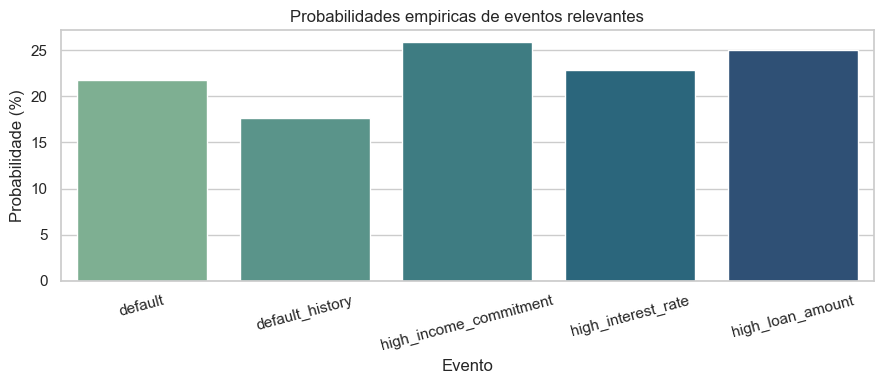

In [4]:
event_probabilities = pd.DataFrame(
    {
        'event': [
            'default',
            'default_history',
            'high_income_commitment',
            'high_interest_rate',
            'high_loan_amount',
        ],
        'probability': [
            df['event_default'].mean(),
            df['event_default_history'].mean(),
            df['event_high_income_commitment'].mean(),
            df['event_high_interest_rate'].mean(),
            df['event_high_loan_amount'].mean(),
        ],
    }
)
event_probabilities['percentage'] = (event_probabilities['probability'] * 100).round(2)
display(event_probabilities)

plt.figure(figsize=(9, 4))
sns.barplot(data=event_probabilities, x='event', y='percentage', hue='event', palette='crest', legend=False)
plt.title('Probabilidades empiricas de eventos relevantes')
plt.xlabel('Evento')
plt.ylabel('Probabilidade (%)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 3. Probabilidade condicional

O objetivo e responder perguntas do tipo: dado um determinado perfil, qual a chance de inadimplencia?

,condition,conditional_default_probability,percentage
0,default_history = Y,0.3781,37.8100
1,high_income_commitment = True,0.4421,44.2100
2,high_interest_rate = True,0.4421,44.2100
3,high_loan_amount = True,0.2977,29.7700


loan_status,0,1
cb_person_default_on_file,,
N,0.8161,0.1839
Y,0.6219,0.3781


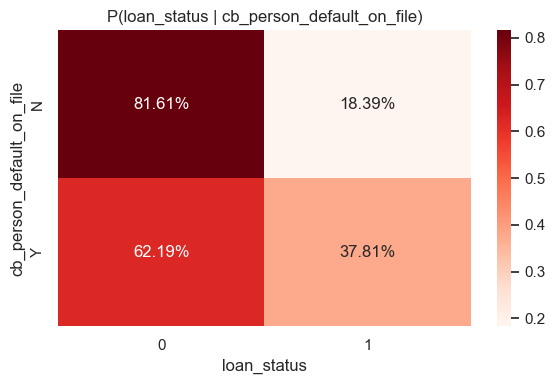

In [5]:
conditional_summary = pd.DataFrame(
    {
        'condition': [
            'default_history = Y',
            'high_income_commitment = True',
            'high_interest_rate = True',
            'high_loan_amount = True',
        ],
        'conditional_default_probability': [
            df.loc[df['event_default_history'], 'event_default'].mean(),
            df.loc[df['event_high_income_commitment'], 'event_default'].mean(),
            df.loc[df['event_high_interest_rate'], 'event_default'].mean(),
            df.loc[df['event_high_loan_amount'], 'event_default'].mean(),
        ],
    }
)
conditional_summary['percentage'] = (conditional_summary['conditional_default_probability'] * 100).round(2)
display(conditional_summary)

history_crosstab = pd.crosstab(
    df['cb_person_default_on_file'],
    df['loan_status'],
    normalize='index'
).round(4)
display(history_crosstab)

plt.figure(figsize=(6, 4))
sns.heatmap(history_crosstab, annot=True, fmt='.2%', cmap='Reds')
plt.title('P(loan_status | cb_person_default_on_file)')
plt.xlabel('loan_status')
plt.ylabel('cb_person_default_on_file')
plt.tight_layout()
plt.show()

## 4. Leitura pratica do Teorema de Bayes

Usamos a relacao entre historico de default e inadimplencia atual para ilustrar o raciocinio bayesiano.

In [6]:
p_default = df['event_default'].mean()
p_history = df['event_default_history'].mean()
p_history_given_default = df.loc[df['event_default'], 'event_default_history'].mean()
p_default_given_history_empirical = df.loc[df['event_default_history'], 'event_default'].mean()
p_default_given_history_bayes = (p_history_given_default * p_default) / p_history

bayes_table = pd.DataFrame(
    {
        'metric': [
            'P(default)',
            'P(history)',
            'P(history | default)',
            'P(default | history) empirico',
            'P(default | history) via Bayes',
        ],
        'value': [
            p_default,
            p_history,
            p_history_given_default,
            p_default_given_history_empirical,
            p_default_given_history_bayes,
        ],
    }
)
bayes_table['percentage'] = (bayes_table['value'] * 100).round(2)
display(bayes_table)

,metric,value,percentage
0,P(default),0.2182,21.8200
1,P(history),0.1763,17.6300
2,P(history | default),0.3056,30.5600
3,P(default | history) empirico,0.3781,37.8100
4,P(default | history) via Bayes,0.3781,37.8100


## 5. Intervalos de confianca por bootstrap

Bootstrap e uma tecnica robusta para quantificar incerteza sem depender fortemente de suposicoes parametricas estritas.

,metric,point_estimate,ci_lower_95,ci_upper_95
0,default_rate,0.2182,0.2137,0.2226
1,mean_loan_int_rate,11.0117,10.9752,11.0487


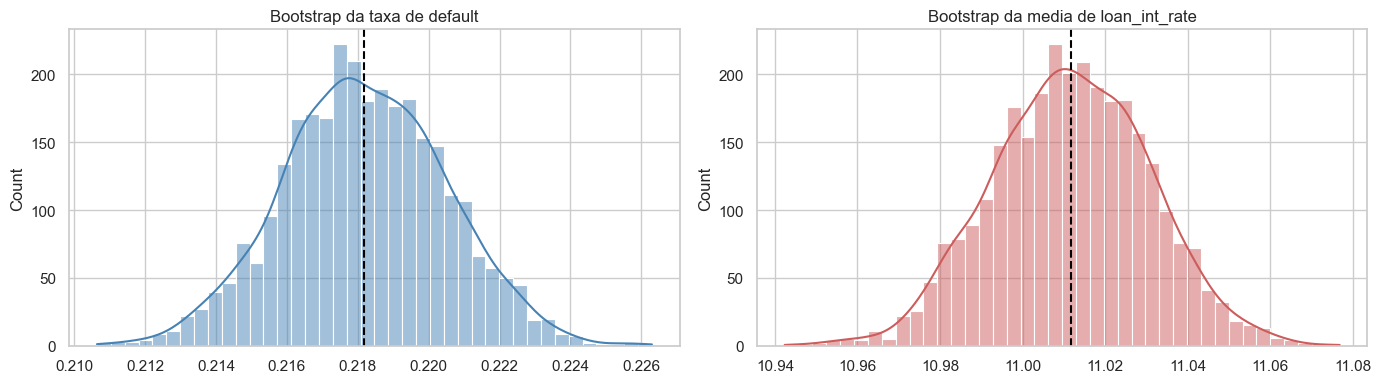

In [7]:
rng = np.random.default_rng(42)


def bootstrap_statistic(values: np.ndarray, statistic, n_bootstrap: int = 3000, seed: int = 42):
    local_rng = np.random.default_rng(seed)
    clean_values = np.asarray(values)
    clean_values = clean_values[~pd.isna(clean_values)]
    draws = []
    for _ in range(n_bootstrap):
        sample = local_rng.choice(clean_values, size=len(clean_values), replace=True)
        draws.append(statistic(sample))
    return np.asarray(draws)


default_bootstrap = bootstrap_statistic(df['loan_status'].to_numpy(), np.mean)
interest_bootstrap = bootstrap_statistic(df['loan_int_rate'].to_numpy(), np.mean)

bootstrap_summary = pd.DataFrame(
    {
        'metric': ['default_rate', 'mean_loan_int_rate'],
        'point_estimate': [df['loan_status'].mean(), df['loan_int_rate'].mean()],
        'ci_lower_95': [np.quantile(default_bootstrap, 0.025), np.quantile(interest_bootstrap, 0.025)],
        'ci_upper_95': [np.quantile(default_bootstrap, 0.975), np.quantile(interest_bootstrap, 0.975)],
    }
)
display(bootstrap_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(default_bootstrap, bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(df['loan_status'].mean(), color='black', linestyle='--')
axes[0].set_title('Bootstrap da taxa de default')

sns.histplot(interest_bootstrap, bins=40, kde=True, ax=axes[1], color='indianred')
axes[1].axvline(df['loan_int_rate'].mean(), color='black', linestyle='--')
axes[1].set_title('Bootstrap da media de loan_int_rate')

plt.tight_layout()
plt.show()

## 6. Testes de hipotese

A seguir testamos diferencas entre grupos e associacoes relevantes para modelagem e entendimento de risco.

In [8]:
default_group = df.loc[df['loan_status'] == 1, 'loan_percent_income'].dropna()
non_default_group = df.loc[df['loan_status'] == 0, 'loan_percent_income'].dropna()

welch_result = stats.ttest_ind(default_group, non_default_group, equal_var=False)

contingency_table = pd.crosstab(df['cb_person_default_on_file'], df['loan_status'])
chi2_stat, chi2_pvalue, chi2_dof, chi2_expected = stats.chi2_contingency(contingency_table)

high_commitment = df.loc[df['event_high_income_commitment'], 'loan_status']
low_commitment = df.loc[~df['event_high_income_commitment'], 'loan_status']
prop_test = stats.ttest_ind(high_commitment, low_commitment, equal_var=False)

hypothesis_tests = pd.DataFrame(
    {
        'test': [
            'Welch t-test: loan_percent_income por loan_status',
            'Chi-square: cb_person_default_on_file vs loan_status',
            'Welch t-test: taxa de default em alto comprometimento vs restante',
        ],
        'statistic': [welch_result.statistic, chi2_stat, prop_test.statistic],
        'p_value': [welch_result.pvalue, chi2_pvalue, prop_test.pvalue],
    }
)
hypothesis_tests['reject_h0_5pct'] = hypothesis_tests['p_value'] < 0.05
display(hypothesis_tests)
display(contingency_table)

,test,statistic,p_value,reject_h0_5pct
0,Welch t-test: loan_percent_income por loan_status,59.0862,0.0000,True
1,Chi-square: cb_person_default_on_file vs loan_...,"1,044.4396",0.0000,True
2,Welch t-test: taxa de default em alto comprome...,51.6253,0.0000,True


loan_status,0,1
cb_person_default_on_file,,
N,21900,4936
Y,3573,2172


## 7. Interpretacao executiva

Fechamos o notebook traduzindo os resultados estatisticos para implicacoes praticas.

In [9]:
high_commitment_default_rate = df.loc[df['event_high_income_commitment'], 'loan_status'].mean() * 100
overall_default_rate = df['loan_status'].mean() * 100
history_default_rate = df.loc[df['event_default_history'], 'loan_status'].mean() * 100

insights = [
    f'- A taxa media de inadimplencia observada na base e de {overall_default_rate:.2f}%.',
    f'- Entre clientes com historico de default em arquivo, a inadimplencia media sobe para {history_default_rate:.2f}%.',
    f'- No quartil superior de comprometimento de renda, a taxa media de default e de {high_commitment_default_rate:.2f}%.',
    f'- O teste de Welch para `loan_percent_income` entre inadimplentes e nao inadimplentes retornou p-value de {welch_result.pvalue:.4g}.',
    f'- O teste qui-quadrado para historico de default e status atual retornou p-value de {chi2_pvalue:.4g}, indicando se ha associacao estatistica entre as variaveis.',
    '- Em termos de modelagem, os resultados sugerem que historico de default e comprometimento de renda sao candidatos fortes para features explicativas.',
]

display(Markdown('\n'.join(insights)))

- A taxa media de inadimplencia observada na base e de 21.82%.
- Entre clientes com historico de default em arquivo, a inadimplencia media sobe para 37.81%.
- No quartil superior de comprometimento de renda, a taxa media de default e de 44.21%.
- O teste de Welch para `loan_percent_income` entre inadimplentes e nao inadimplentes retornou p-value de 0.
- O teste qui-quadrado para historico de default e status atual retornou p-value de 3.935e-229, indicando se ha associacao estatistica entre as variaveis.
- Em termos de modelagem, os resultados sugerem que historico de default e comprometimento de renda sao candidatos fortes para features explicativas.